# 머신러닝 과제 2: YOLOv8 fine-tuning — 수족관 생물 3개 부류 감지·추적

위에서부터 순서대로 실행하면 과제에 필요한 산출물이 모두 만들어집니다.

| 과제 요구사항 (강의자료 49쪽) | 이 노트북의 단계 |
|---|---|
| 3개 부류, 100개 이상의 이미지 수집 | 2~4단계 |
| 3개 부류에 대한 학습 | 6~7단계 |
| 객체 감지 및 추적 결과 5초 동영상 | 10단계 |
| GitHub에 학습 모델·동영상 저장과 공개 | 11~12단계 |
| 결과보고서 (학습 과정 및 성능, GitHub 링크, 경험한 내용) | 8~9단계 결과, 13단계 |

**실행 전 준비**
1. 메뉴 `런타임 → 런타임 유형 변경`에서 **T4 GPU** 선택
2. Roboflow 무료 계정 (2단계에서 데이터를 받을 때 필요)
3. 수족관 영상 1~3개 (10단계 전까지만 준비하면 됩니다)

런타임이 끊기면 `/content`의 파일이 사라지므로, 한 번에 끝까지 실행하는 것을 권합니다. 학습 두 번을 포함해 T4 GPU에서 대략 30~40분을 예상하면 됩니다.

## 1. 환경 준비

In [1]:
# ultralytics: YOLO 학습·추론 라이브러리 / roboflow: 데이터셋 다운로드 도구 / lap: 추적기가 쓰는 매칭 라이브러리
!pip install -q ultralytics roboflow lap

In [2]:
import shutil                                  # 파일 복사, 폴더 삭제
import subprocess                              # ffmpeg 같은 외부 명령 실행
import zipfile                                 # zip 압축 풀기·만들기
from collections import defaultdict, deque     # 부류별 집계, 이동 궤적 저장용 자료구조
from pathlib import Path                       # 경로를 객체로 다루기

import cv2                                     # 영상 읽기·쓰기, 도형 그리기
import matplotlib.pyplot as plt                # 그래프와 이미지 표시
import numpy as np                             # 배열 연산
import pandas as pd                            # 표 형태 데이터 처리
import torch                                   # GPU 사용 가능 여부 확인
import ultralytics                             # 버전 확인용
import yaml                                    # data.yaml 읽기·쓰기
from IPython.display import Image, Video, display   # 노트북 안에 이미지·영상·표 표시
from ultralytics import YOLO                   # YOLO 모델 클래스

try:                                           # Colab에서만 제공되는 모듈
    from google.colab import files             # 파일 업로드·다운로드 도구
    IN_COLAB = True                            # Colab에서 실행 중
except ImportError:                            # 내 컴퓨터 등 다른 환경
    files = None                               # 업로드 도구 없음
    IN_COLAB = False                           # Colab이 아님

BASE = Path("/content") if IN_COLAB else Path.cwd()   # 모든 파일을 둘 작업 폴더
RAW_DIR = BASE / "aquarium_raw"                # Roboflow 원본 데이터 (7개 부류)
DATA_DIR = BASE / "aquarium3"                  # 3개 부류만 남긴 학습용 데이터
RUNS_DIR = BASE / "runs_aquarium"              # 학습·평가 결과가 쌓이는 폴더
VIDEO_DIR = BASE / "videos"                    # 추적에 쓸 원본 영상
WORK_DIR = BASE / "video_work"                 # 영상 작업용 임시 폴더
OUT_DIR = BASE / "submission"                  # GitHub에 올릴 제출 폴더
RUNS_DIR.mkdir(parents=True, exist_ok=True)    # 결과 폴더 미리 생성

print("Ultralytics 버전:", ultralytics.__version__)   # 보고서에 적을 라이브러리 버전
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 → CPU로 실행 (매우 느림, 런타임 유형을 확인하세요)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 버전: 8.4.216
GPU: Tesla T4


## 2. 데이터 다운로드

Roboflow의 공개 데이터셋 **Aquarium Combined** (638장, 7개 부류, CC BY 4.0)를 받습니다.
버전 2(`raw-1024`)는 증강을 적용하지 않은 버전입니다. 증강은 학습할 때 Ultralytics가 자동으로 해줍니다.

아래 셀을 실행하면 입력 칸이 나옵니다. 두 방법 중 하나를 쓰세요.

- **방법 A (API 키, 권장)**: Roboflow에 로그인 → 설정(Settings)의 API Keys에서 Private API Key 복사 → 입력 칸에 붙여넣기.
  키는 화면과 노트북 파일에 남지 않습니다. zip을 올리는 것보다 빠릅니다.
- **방법 B (zip 업로드)**: [데이터셋 페이지](https://universe.roboflow.com/brad-dwyer/aquarium-combined/dataset/2)에서
  `Download Dataset → YOLOv8 → zip 다운로드`로 받은 뒤, 입력 칸에서 그냥 Enter를 누르고 zip 파일을 올리기.

In [3]:
from getpass import getpass                    # 입력한 내용이 화면과 노트북에 남지 않는 입력 함수

WORKSPACE = "brad-dwyer"                       # 데이터셋이 올라가 있는 Roboflow 워크스페이스
PROJECT = "aquarium-combined"                  # 데이터셋(프로젝트) 이름
VERSION = 2                                    # 버전 2 = raw-1024 (증강 없는 원본)


def find_dataset_root(folder):
    """folder 아래에서 data.yaml이 들어 있는 폴더를 찾아 돌려준다. 없으면 None."""
    hits = sorted(Path(folder).rglob("data.yaml"))    # 하위 폴더까지 data.yaml 검색
    return hits[0].parent if hits else None           # 처음 찾은 파일이 있는 폴더


def extract_zip(zip_path):
    """Roboflow에서 받은 zip을 RAW_DIR에 푼다."""
    with zipfile.ZipFile(zip_path) as zf:             # zip 파일 열기
        zf.extractall(RAW_DIR)                        # 전체 압축 해제


if find_dataset_root(RAW_DIR) is None:                # 아직 받은 데이터가 없을 때만 실행
    api_key = getpass("Roboflow API 키 입력 (zip 파일을 올리려면 그냥 Enter): ").strip()
    if api_key:                                       # 방법 A: API 키로 바로 다운로드
        from roboflow import Roboflow                 # Roboflow 파이썬 도구
        rf = Roboflow(api_key=api_key)                # 내 계정으로 접속
        project = rf.workspace(WORKSPACE).project(PROJECT)                   # 공개 데이터셋 선택
        project.version(VERSION).download("yolov8", location=str(RAW_DIR))   # YOLOv8 형식으로 저장
    elif IN_COLAB:                                    # 방법 B: 내 컴퓨터의 zip 업로드
        for zip_name in files.upload():               # 파일 선택 창이 열리고, 올린 파일 이름이 차례로 나옴
            extract_zip(zip_name)                     # 올린 zip 풀기
    else:                                             # Colab이 아닐 때: 작업 폴더에 둔 zip 사용
        for zip_path in sorted(BASE.glob("*.zip")):   # 작업 폴더의 zip 파일들
            if zip_path.stem != OUT_DIR.name:         # 이 노트북이 만든 제출용 zip은 제외
                extract_zip(zip_path)                 # 데이터 zip 풀기

RAW_ROOT = find_dataset_root(RAW_DIR)                 # data.yaml이 있는 실제 데이터 폴더
assert RAW_ROOT is not None, "데이터를 찾지 못했습니다. API 키 또는 zip 파일을 확인한 뒤 이 셀을 다시 실행하세요."
print("원본 데이터 위치:", RAW_ROOT)

Roboflow API 키 입력 (zip 파일을 올리려면 그냥 Enter): ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/aquarium_raw in yolov8:: 100%|██████████| 1288/1288 [00:00<00:00, 4986.75it/s]

원본 데이터 위치: /content/aquarium_raw


## 3. 데이터 살펴보기

부류마다 이미지 수와 상자 수가 얼마나 되는지 셉니다. 이 표를 보고 4단계에서 3개 부류를 정합니다.

- `images`: 그 부류가 한 번이라도 등장하는 이미지 수
- `boxes`: 그 부류의 경계 상자(라벨) 수

In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}   # 이미지로 취급할 확장자
SPLITS = ["train", "valid", "test"]                      # Roboflow 내보내기의 분할 폴더 이름

raw_cfg = yaml.safe_load((RAW_ROOT / "data.yaml").read_text(encoding="utf-8"))   # 원본 설정 파일 읽기
raw_names = raw_cfg["names"]                             # 부류 이름들
if isinstance(raw_names, dict):                          # {0: 'fish', 1: ...} 형태라면
    raw_names = [raw_names[k] for k in sorted(raw_names)]   # 번호 순서의 목록으로 변환
raw_names = [str(n) for n in raw_names]                  # 이름을 모두 문자열로 통일
print("원본 부류:", raw_names)


def read_label(label_path):
    """YOLO 라벨 파일을 읽어 (부류 번호, 중심x, 중심y, 너비, 높이) 목록으로 돌려준다."""
    rows = []                                            # 결과를 담을 목록
    if not label_path.exists():                          # 라벨 파일이 없으면 (객체 없는 이미지)
        return rows                                      # 빈 목록
    for line in label_path.read_text().splitlines():     # 한 줄이 상자 하나
        values = line.split()                            # 공백으로 나누기
        if len(values) < 5:                              # 값이 모자란 줄은
            continue                                     # 건너뜀
        cls = int(float(values[0]))                      # 첫 값은 부류 번호
        nums = [float(v) for v in values[1:]]            # 나머지는 좌표 (0~1로 정규화된 값)
        if len(nums) > 4:                                # 다각형(x1 y1 x2 y2 ...) 형식이면
            xs, ys = nums[0::2], nums[1::2]              # x좌표들과 y좌표들로 분리
            cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2   # 다각형을 감싸는 상자의 중심
            w, h = max(xs) - min(xs), max(ys) - min(ys)                 # 감싸는 상자의 너비와 높이
        else:                                            # 일반 상자 형식이면
            cx, cy, w, h = nums                          # 그대로 사용
        if 0 <= cls < len(raw_names):                    # 부류 번호가 정상 범위일 때만
            rows.append((cls, cx, cy, w, h))             # 목록에 추가
    return rows


def list_pairs(split):
    """한 분할 폴더의 (이미지 경로, 라벨 경로) 목록을 돌려준다."""
    img_dir = RAW_ROOT / split / "images"                # 이미지 폴더
    lbl_dir = RAW_ROOT / split / "labels"                # 라벨 폴더
    if not img_dir.exists():                             # 이 분할이 없으면
        return []                                        # 빈 목록
    imgs = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXTS)   # 이미지 파일만 정렬해서 모음
    return [(p, lbl_dir / (p.stem + ".txt")) for p in imgs]                       # 같은 이름의 라벨과 짝짓기


def class_stats(items, names):
    """부류별 이미지 수와 상자 수를 표로 만든다."""
    cols = ["images", "boxes"] + [f"images_{s}" for s in SPLITS]      # 표의 열 이름
    table = pd.DataFrame(0, index=names, columns=cols)                # 0으로 채운 표
    for split, _, labels in items:                                    # 이미지 한 장씩
        for cls in set(row[0] for row in labels):                     # 이 이미지에 등장한 부류마다
            table.loc[names[cls], "images"] += 1                      # 전체 이미지 수 +1
            table.loc[names[cls], f"images_{split}"] += 1             # 분할별 이미지 수 +1
        for row in labels:                                            # 상자 하나씩
            table.loc[names[row[0]], "boxes"] += 1                    # 상자 수 +1
    return table.sort_values("images", ascending=False)               # 이미지가 많은 순서로 정렬


all_items = []                                           # (분할, 이미지 경로, 라벨 목록) 전체
for split in SPLITS:                                     # train, valid, test 차례로
    for img_path, lbl_path in list_pairs(split):         # 이미지와 라벨 짝마다
        all_items.append((split, img_path, read_label(lbl_path)))   # 라벨을 읽어 저장

stats = class_stats(all_items, raw_names)                # 원본 7개 부류 통계
print(f"전체 이미지: {len(all_items)}장")
display(stats)

원본 부류: ['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray']
전체 이미지: 638장


,images,boxes,images_train,images_valid,images_test
fish,333,2669,240,63,30
shark,176,354,134,28,14
stingray,124,184,91,23,10
penguin,71,516,47,17,7
puffin,66,284,45,15,6
starfish,59,116,37,17,5
jellyfish,52,694,32,9,11


## 4. 3개 부류 선택과 데이터 재구성

선택한 3개 부류의 상자만 남기고 부류 번호를 0, 1, 2로 다시 매깁니다.

- `TARGET_CLASSES = None`이면 이미지 수가 많은 순서로 3개를 자동 선택합니다.
- 직접 고르려면 위 표의 이름 그대로 적으세요. 예: `["fish", "shark", "jellyfish"]`
- **10단계의 영상에 이 3개 부류가 나와야 하므로**, 영상을 구하기 쉬운 부류인지도 함께 고려하세요.

과제 조건은 "100개 이상의 이미지"입니다. 아래 셀이 전체 이미지 수와 부류별 이미지 수를 확인해 줍니다.

In [5]:
TARGET_CLASSES = None      # None: 이미지 수 상위 3개 자동 선택 / 직접 지정 예: ["fish", "shark", "jellyfish"]
KEEP_BACKGROUND = False    # True: 선택한 부류가 하나도 없는 이미지도 '배경' 예시로 남김
SPLIT_SEED = 0             # 분할을 새로 나눠야 할 때 쓰는 난수 시드

if TARGET_CLASSES is None:                                # 자동 선택이면
    TARGET_CLASSES = stats.index[:3].tolist()             # 이미지 수 상위 3개 부류
unknown = [c for c in TARGET_CLASSES if c not in raw_names]   # 데이터에 없는 이름 찾기
assert not unknown, f"{unknown} 은(는) 데이터에 없는 이름입니다. 가능한 이름: {raw_names}"
assert len(set(TARGET_CLASSES)) == 3, "부류는 서로 다른 3개여야 합니다."
id_map = {raw_names.index(n): i for i, n in enumerate(TARGET_CLASSES)}   # 원래 번호 → 새 번호(0, 1, 2)

items3 = []                                               # 3개 부류만 남긴 (분할, 이미지, 라벨) 목록
for split, img_path, labels in all_items:                 # 원본 이미지 한 장씩
    kept = [(id_map[c], cx, cy, w, h) for c, cx, cy, w, h in labels if c in id_map]   # 선택 부류만, 새 번호로
    if kept or KEEP_BACKGROUND:                           # 남은 상자가 있거나 배경도 남기는 설정이면
        items3.append([split, img_path, kept])            # 목록에 추가

split_counts = {s: sum(1 for it in items3 if it[0] == s) for s in SPLITS}   # 분할별 이미지 수
if min(split_counts.values()) == 0:                       # valid나 test가 비어 있으면 새로 나눔
    order = np.random.default_rng(SPLIT_SEED).permutation(len(items3))   # 무작위 순서
    n_train, n_valid = int(len(items3) * 0.7), int(len(items3) * 0.2)    # 70% 학습, 20% 검증, 나머지 시험
    for rank, idx in enumerate(order):                    # 섞인 순서대로 분할 배정
        items3[idx][0] = "train" if rank < n_train else "valid" if rank < n_train + n_valid else "test"

if DATA_DIR.exists():                                     # 이전에 만든 폴더가 있으면
    shutil.rmtree(DATA_DIR)                               # 지우고 새로 만듦
for split in SPLITS:                                      # 분할마다
    (DATA_DIR / split / "images").mkdir(parents=True)     # 이미지 폴더 생성
    (DATA_DIR / split / "labels").mkdir(parents=True)     # 라벨 폴더 생성
for split, img_path, kept in items3:                      # 이미지 한 장씩
    shutil.copy2(img_path, DATA_DIR / split / "images" / img_path.name)   # 이미지 복사
    lines = [f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for c, cx, cy, w, h in kept]   # YOLO 라벨 형식의 줄
    (DATA_DIR / split / "labels" / (img_path.stem + ".txt")).write_text("\n".join(lines))   # 새 라벨 저장

DATA_YAML = DATA_DIR / "data.yaml"                        # 학습에 쓸 설정 파일
DATA_YAML.write_text(yaml.safe_dump({
    "path": str(DATA_DIR),                                # 데이터 최상위 폴더 (절대 경로)
    "train": "train/images",                              # 학습용 이미지
    "val": "valid/images",                                # 검증용 이미지
    "test": "test/images",                                # 시험용 이미지
    "names": {i: n for i, n in enumerate(TARGET_CLASSES)},   # 새 부류 번호와 이름
}, sort_keys=False, allow_unicode=True), encoding="utf-8")

stats3 = class_stats(items3, TARGET_CLASSES)              # 3개 부류 통계
split_counts = {s: sum(1 for it in items3 if it[0] == s) for s in SPLITS}   # 분할별 이미지 수 다시 계산
stats3.to_csv(RUNS_DIR / "dataset_stats.csv")             # 보고서·README용으로 저장

print("선택한 부류:", TARGET_CLASSES)
print(f"전체 이미지: {len(items3)}장 (train {split_counts['train']} / valid {split_counts['valid']} / test {split_counts['test']})")
display(stats3)
print("전체 100장 이상:", "충족" if len(items3) >= 100 else "미달 → 부류를 다시 고르세요")
for cls_name, n_img in stats3["images"].items():          # 부류별 이미지 수 확인
    if n_img < 100:                                       # 100장이 안 되는 부류는 알림
        print(f"참고: '{cls_name}' 부류는 이미지가 {n_img}장입니다. 부류당 100장을 맞추려면 다른 부류를 고르세요.")

선택한 부류: ['fish', 'shark', 'stingray']
전체 이미지: 408장 (train 297 / valid 77 / test 34)


,images,boxes,images_train,images_valid,images_test
fish,333,2669,240,63,30
shark,176,354,134,28,14
stingray,124,184,91,23,10


전체 100장 이상: 충족


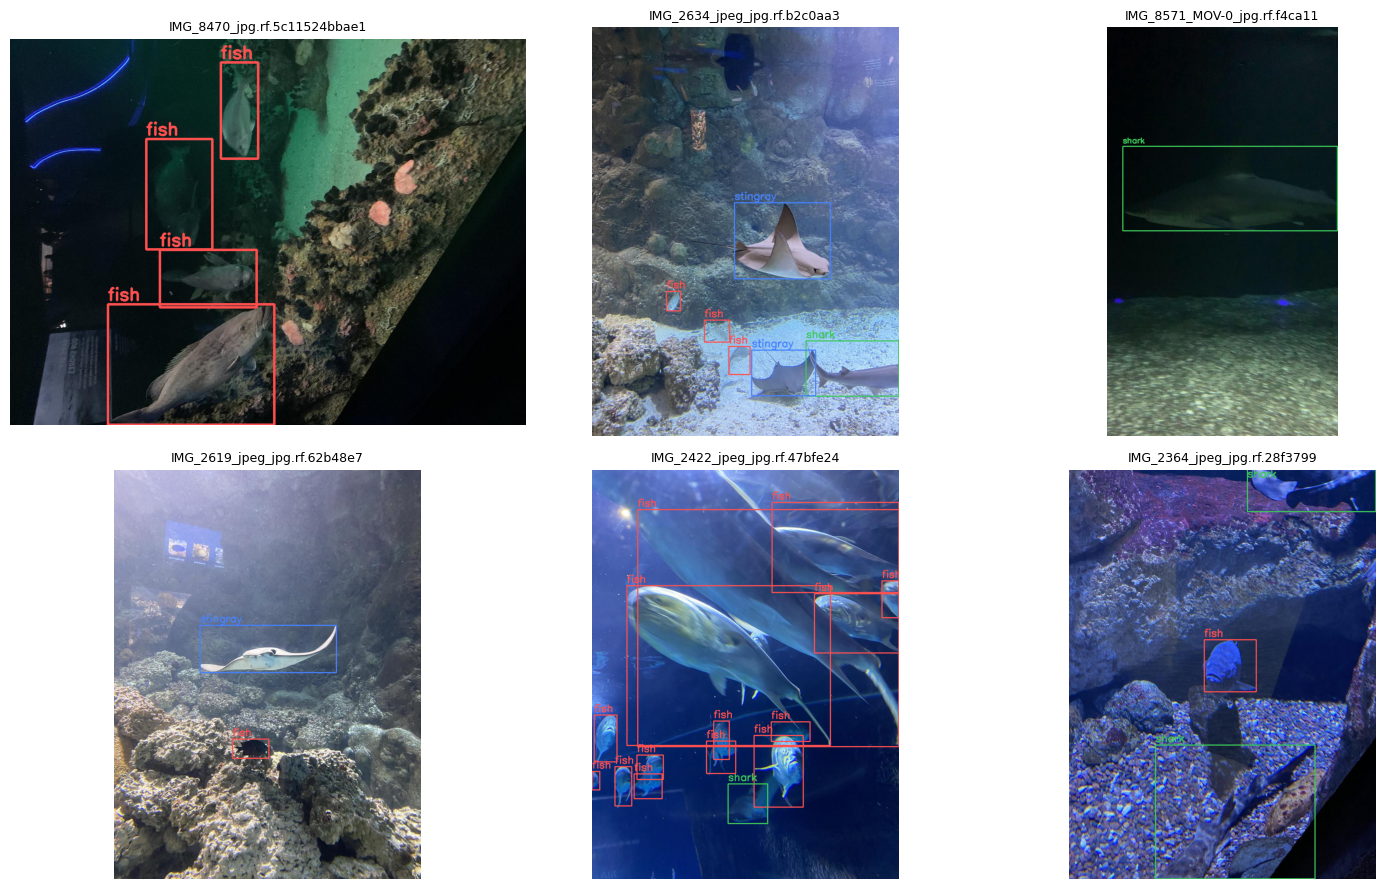

In [6]:
COLORS = [(255, 80, 80), (60, 200, 90), (70, 130, 255)]   # 부류별 상자 색 (RGB)


def draw_labels(img_path, labels):
    """이미지에 정답 상자와 부류 이름을 그려서 돌려준다."""
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)   # 이미지 읽고 BGR → RGB
    h, w = img.shape[:2]                                  # 이미지 높이와 너비
    thick = max(2, w // 300)                              # 이미지 크기에 맞춘 선 굵기
    font_scale = max(0.5, w / 900)                        # 이미지 크기에 맞춘 글자 크기
    for c, cx, cy, bw, bh in labels:                      # 상자 하나씩
        x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)   # 왼쪽 위 꼭짓점 (픽셀)
        x2, y2 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)   # 오른쪽 아래 꼭짓점 (픽셀)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[c], thick)  # 상자 그리기
        cv2.putText(img, TARGET_CLASSES[c], (x1, max(y1 - 8, 20)),   # 상자 위에 부류 이름
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, COLORS[c], thick)
    return img


train_items = [it for it in items3 if it[0] == "train"]   # 학습용 이미지들
picks = np.random.default_rng(1).choice(len(train_items), size=min(6, len(train_items)), replace=False)   # 무작위 6장
fig, axes = plt.subplots(2, 3, figsize=(15, 9))           # 2행 3열 그림판
for ax in axes.ravel():                                   # 모든 칸의
    ax.axis("off")                                        # 축 눈금 숨김
for ax, idx in zip(axes.ravel(), picks):                  # 칸마다 이미지 한 장
    _, img_path, kept = train_items[idx]                  # 고른 이미지와 라벨
    ax.imshow(draw_labels(img_path, kept))                # 정답 상자를 그려 표시
    ax.set_title(img_path.name[:28], fontsize=9)          # 파일 이름을 제목으로
plt.tight_layout()                                        # 여백 정리
plt.savefig(RUNS_DIR / "dataset_samples.png", dpi=120)    # 보고서·README용으로 저장
plt.show()

## 5. fine-tuning 전: 사전학습 모델로 예측해 보기

COCO 80개 부류로 사전학습된 YOLOv8에는 물고기·상어·해파리 같은 부류가 없습니다.
그래서 학습 전에는 못 잡거나 엉뚱한 부류(bird, kite 등)로 잡습니다. 9단계에서 학습 후 결과와 나란히 비교합니다.

`MODEL`은 사전학습 가중치입니다. `yolov8n.pt`는 가장 빠르고, `yolov8s.pt`는 더 정확하지만 학습이 조금 더 걸립니다.

IMG_2371_jpeg_jpg.rf.54505f6 → ['bird']
IMG_2423_jpeg_jpg.rf.1c09018 → ['bird', 'bird']
IMG_2496_jpeg_jpg.rf.3f91e7f → ['bird']


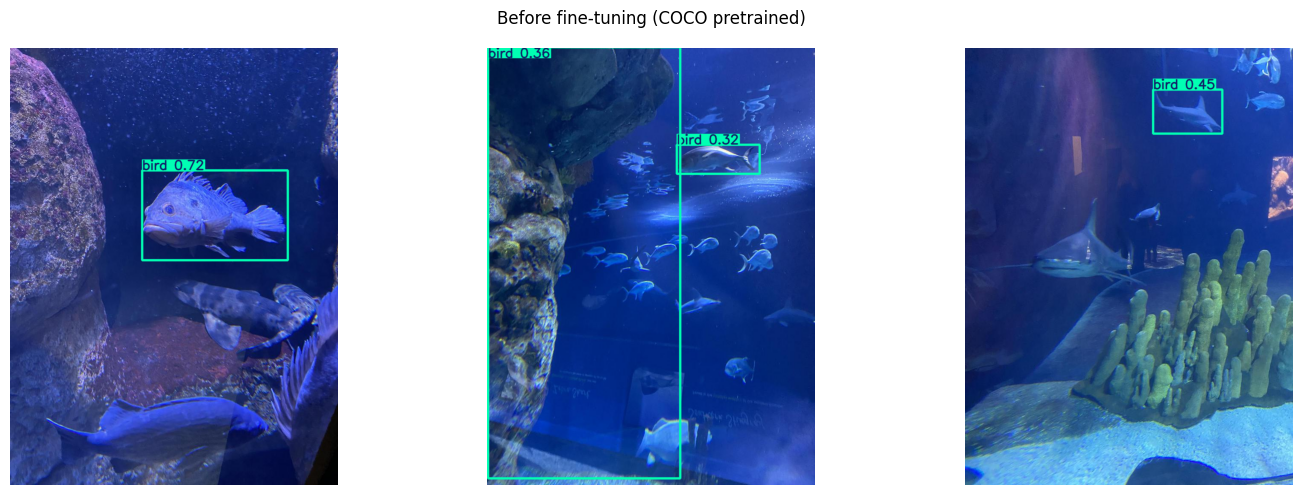

In [7]:
MODEL = "yolov8s.pt"       # 사전학습 가중치: "yolov8n.pt"(빠름) 또는 "yolov8s.pt"(더 정확)

test_items = [it for it in items3 if it[0] == "test"]     # 시험용 이미지들
demo_imgs = []                                            # 비교에 쓸 이미지 3장
for c in range(3):                                        # 부류마다 한 장씩 고름
    for _, img_path, kept in test_items:                  # 시험용 이미지를 차례로 보면서
        if any(row[0] == c for row in kept) and img_path not in demo_imgs:   # 그 부류가 있고 아직 안 고른 이미지면
            demo_imgs.append(img_path)                    # 선택
            break                                         # 다음 부류로
for _, img_path, _ in test_items:                         # 3장이 안 되면 남은 이미지로 채움
    if len(demo_imgs) < 3 and img_path not in demo_imgs:
        demo_imgs.append(img_path)
demo_imgs = [DATA_DIR / "test" / "images" / p.name for p in demo_imgs]   # 재구성한 폴더의 경로로 변환

coco_model = YOLO(MODEL)                                  # COCO로 사전학습된 모델 불러오기
before_imgs = []                                          # 학습 전 예측 그림들
for img_path in demo_imgs:                                # 이미지마다
    result = coco_model.predict(str(img_path), conf=0.25, verbose=False)[0]   # 예측 실행
    before_imgs.append(result.plot()[..., ::-1])          # 예측을 그린 그림 (BGR → RGB)
    found = [coco_model.names[int(c)] for c in result.boxes.cls]              # 감지된 부류 이름들
    print(img_path.name[:28], "→", found if found else "감지 없음")

fig, axes = plt.subplots(1, len(before_imgs), figsize=(15, 5))   # 가로로 나란히
for ax, img in zip(np.atleast_1d(axes), before_imgs):     # 칸마다 그림 하나
    ax.imshow(img)                                        # 표시
    ax.axis("off")                                        # 축 숨김
plt.suptitle("Before fine-tuning (COCO pretrained)")      # 그림 제목
plt.tight_layout()
plt.show()

## 6. 학습 ①: 전체 fine-tuning

사전학습 가중치에서 출발해 모든 층을 3개 부류 데이터로 다시 학습합니다.
데이터의 부류 수가 3개이므로 검출 헤드의 출력이 80개에서 3개로 자동 변경됩니다
(강의자료 48쪽 "응용분야의 출력 클래스 개수에 맞게 모델 구조 변경").

학습이 끝난 실험은 다시 실행해도 건너뜁니다. 설정을 바꿔 다시 학습하려면 `FORCE_RETRAIN = True`로 바꾸세요.

In [8]:
EPOCHS = 60                # 전체 데이터를 반복 학습하는 횟수
IMGSZ = 640                # 학습·추론 때 이미지 크기 (긴 변 기준, 픽셀)
BATCH = 16                 # 한 번에 처리하는 이미지 수
SEED = 0                   # 결과 재현을 위한 난수 시드
PATIENCE = 20              # 검증 성능이 이만큼의 epoch 동안 안 오르면 조기 종료
FORCE_RETRAIN = False      # True: 이미 끝난 실험도 처음부터 다시 학습


def train_run(name, **extra):
    """실험 하나를 학습하고 가장 좋은 가중치(best.pt)의 경로를 돌려준다."""
    best = RUNS_DIR / name / "weights" / "best.pt"        # 이 실험의 최고 성능 가중치 위치
    if best.exists() and not FORCE_RETRAIN:               # 이미 학습이 끝났으면
        print(f"'{name}' 실험은 이미 학습되어 건너뜁니다:", best)
        return best                                       # 기존 결과 사용
    model = YOLO(MODEL)                                   # 사전학습 가중치에서 출발
    model.train(
        data=str(DATA_YAML),                              # 4단계에서 만든 3개 부류 데이터
        epochs=EPOCHS,                                    # 반복 횟수
        imgsz=IMGSZ,                                      # 이미지 크기
        batch=BATCH,                                      # 배치 크기
        seed=SEED,                                        # 난수 시드
        patience=PATIENCE,                                # 조기 종료 기준
        project=str(RUNS_DIR),                            # 결과를 저장할 상위 폴더
        name=name,                                        # 실험 이름 (하위 폴더 이름)
        exist_ok=True,                                    # 같은 이름의 폴더가 있으면 덮어씀
        **extra,                                          # 실험마다 다른 추가 설정 (예: freeze)
    )
    return best


best_full = train_run("full")                             # 실험 ①: 모든 층을 학습

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/aquarium3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=full, nbs=64, nms=None, opset=None, optimize=False, optimizer

## 7. 학습 ②: 백본을 동결한 전이학습

강의자료 48쪽의 전이학습 설명과 같은 방식입니다.

1. 학습된 모델의 특징 추출 부분 사용 → `freeze=10`으로 백본(0~9번 층)의 가중치를 고정
2. 출력 클래스 개수에 맞게 모델 구조 변경 → 검출 헤드 출력이 3개로 변경
3. 변경된 후반부 구조만 학습 → 넥과 헤드만 학습

실험 ①과 성능을 비교해 보고서의 "학습 과정 및 성능"에 넣습니다.

In [9]:
FREEZE = 10                # 앞에서부터 고정할 층의 수 (YOLOv8의 백본은 0~9번 층)

best_freeze = train_run("freeze", freeze=FREEZE)          # 실험 ②: 백본은 고정하고 넥과 헤드만 학습

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/aquarium3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=freeze, nbs=64, nms=None, opset=None, optimize=False, optimizer

## 8. 성능 평가와 비교

학습에 쓰지 않은 **test 분할**로 두 실험을 평가합니다. 지표는 강의자료 6절의 내용과 같습니다.

- **P (Precision)**: 모델이 감지했다고 한 것 중 실제로 맞은 비율
- **R (Recall)**: 실제 객체 중 모델이 찾아낸 비율
- **mAP50**: IoU 0.5를 기준으로 맞고 틀림을 판정했을 때의 AP를 부류에 대해 평균한 값
- **mAP50-95**: IoU 기준을 0.5부터 0.95까지 바꿔가며 구한 AP의 평균 (위치가 정확해야 높게 나옴)

In [10]:
EXPERIMENTS = {"full": best_full, "freeze": best_freeze}  # 실험 이름과 가중치 경로


def evaluate(name, weights):
    """test 분할에서 성능을 재고, 전체와 부류별 지표를 행 목록으로 돌려준다."""
    metrics = YOLO(str(weights)).val(
        data=str(DATA_YAML),                              # 3개 부류 데이터
        split="test",                                     # 시험용 분할로 평가
        imgsz=IMGSZ,                                      # 학습 때와 같은 이미지 크기
        project=str(RUNS_DIR),                            # 평가 결과 저장 위치
        name=f"{name}_test",                              # 평가 결과 폴더 이름
        exist_ok=True,                                    # 다시 실행하면 덮어씀
        verbose=False,                                    # 자세한 출력 생략
    )
    rows = [{"experiment": name, "class": "all",          # 첫 행: 전체 부류 평균
             "P": metrics.box.mp, "R": metrics.box.mr,
             "mAP50": metrics.box.map50, "mAP50-95": metrics.box.map}]
    for i, cls_id in enumerate(metrics.box.ap_class_index):   # 부류별 행
        p, r, ap50, ap = metrics.box.class_result(i)      # 그 부류의 P, R, AP50, AP50-95
        rows.append({"experiment": name, "class": metrics.names[int(cls_id)],
                     "P": p, "R": r, "mAP50": ap50, "mAP50-95": ap})
    return rows


metric_rows = []                                          # 모든 실험의 지표
for exp_name, weights in EXPERIMENTS.items():             # 실험마다
    metric_rows += evaluate(exp_name, weights)            # 평가해서 행 추가
metrics_df = pd.DataFrame(metric_rows)                    # 표로 변환
for col in ["P", "R", "mAP50", "mAP50-95"]:               # 숫자 열을
    metrics_df[col] = metrics_df[col].astype(float).round(4)   # 소수 넷째 자리까지
metrics_df.to_csv(RUNS_DIR / "metrics_test.csv", index=False)  # 보고서·README용으로 저장
display(metrics_df)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 27.2±11.1 MB/s, size: 83.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/aquarium3/test/labels... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 401.8it/s 0.1s
val: New cache created: /content/aquarium3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.3it/s 1.3s
                   all         34        302      0.901      0.712      0.835      0.566
Speed: 1.9ms preprocess, 13.3ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs_aquarium/full_test
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Te

,experiment,class,P,R,mAP50,mAP50-95
0,full,all,0.9014,0.7123,0.8349,0.5660
1,full,fish,0.8929,0.6265,0.7983,0.4864
2,full,shark,0.8257,0.7105,0.7803,0.5392
3,full,stingray,0.9855,0.8000,0.9262,0.6722
4,freeze,all,0.8098,0.7058,0.8184,0.5120
5,freeze,fish,0.7910,0.6990,0.7710,0.4423
6,freeze,shark,0.7245,0.7105,0.7830,0.5013
7,freeze,stingray,0.9138,0.7078,0.9011,0.5924


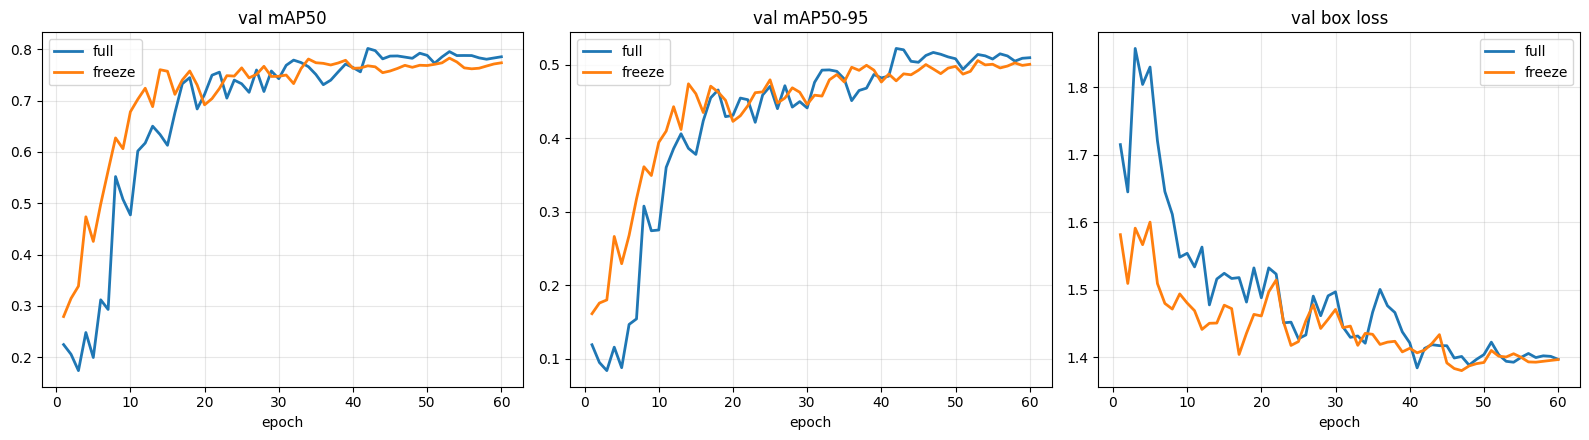

,experiment,epochs_run,best_epoch,val_mAP50,val_mAP50-95,train_minutes
0,full,60,42,0.8014,0.5224,6.4
1,freeze,60,53,0.7825,0.5058,5.5


최종 선택 모델: full → /content/runs_aquarium/full/weights/best.pt


In [11]:
def load_history(name):
    """실험의 epoch별 학습 기록(results.csv)을 표로 읽는다."""
    history = pd.read_csv(RUNS_DIR / name / "results.csv")   # Ultralytics가 저장한 학습 기록
    history.columns = [c.strip() for c in history.columns]   # 열 이름의 앞뒤 공백 제거
    return history


histories = {name: load_history(name) for name in EXPERIMENTS}   # 실험별 학습 기록
curve_cols = [("metrics/mAP50(B)", "val mAP50"),          # (기록의 열 이름, 그래프 제목)
              ("metrics/mAP50-95(B)", "val mAP50-95"),
              ("val/box_loss", "val box loss")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))         # 그래프 3개를 가로로
for ax, (col, title) in zip(axes, curve_cols):            # 그래프마다
    for name, history in histories.items():               # 실험마다 선 하나
        ax.plot(history["epoch"], history[col], label=name, linewidth=2)   # epoch에 따른 변화
    ax.set_title(title)                                   # 그래프 제목
    ax.set_xlabel("epoch")                                # 가로축 이름
    ax.grid(alpha=0.3)                                    # 옅은 격자
    ax.legend()                                           # 범례
plt.tight_layout()
plt.savefig(RUNS_DIR / "compare_curves.png", dpi=120)     # 보고서·README용으로 저장
plt.show()

summary_rows = []                                         # 실험별 요약
for name, history in histories.items():                   # 실험마다
    best_row = history.loc[history["metrics/mAP50-95(B)"].idxmax()]   # 검증 mAP50-95가 가장 높은 epoch
    summary_rows.append({
        "experiment": name,                               # 실험 이름
        "epochs_run": int(history["epoch"].max()),        # 실제로 학습한 epoch 수 (조기 종료 반영)
        "best_epoch": int(best_row["epoch"]),             # 최고 성능이 나온 epoch
        "val_mAP50": round(float(best_row["metrics/mAP50(B)"]), 4),        # 그때의 검증 mAP50
        "val_mAP50-95": round(float(best_row["metrics/mAP50-95(B)"]), 4),  # 그때의 검증 mAP50-95
        "train_minutes": round(float(history["time"].max()) / 60, 1) if "time" in history else None,   # 학습 시간(분)
    })
summary_df = pd.DataFrame(summary_rows)                   # 표로 변환
summary_df.to_csv(RUNS_DIR / "train_summary.csv", index=False)   # 저장
display(summary_df)

BEST_NAME = summary_df.sort_values("val_mAP50-95", ascending=False).iloc[0]["experiment"]   # 검증 성능이 더 좋은 실험
BEST_WEIGHTS = EXPERIMENTS[BEST_NAME]                     # 그 실험의 가중치 → 영상 제작과 제출에 사용
print("최종 선택 모델:", BEST_NAME, "→", BEST_WEIGHTS)

아래는 선택된 모델의 학습 곡선, 혼동 행렬, PR 곡선입니다.

- **학습 곡선**: 손실이 줄고 mAP가 오르다가 평평해지면 학습이 수렴한 것입니다.
- **혼동 행렬**: 어떤 부류를 어떤 부류로 착각했는지, 배경으로 놓친 것이 얼마나 되는지 보여줍니다.
- **PR 곡선**: 곡선 아래 면적이 AP입니다 (강의자료 45쪽).

results.png


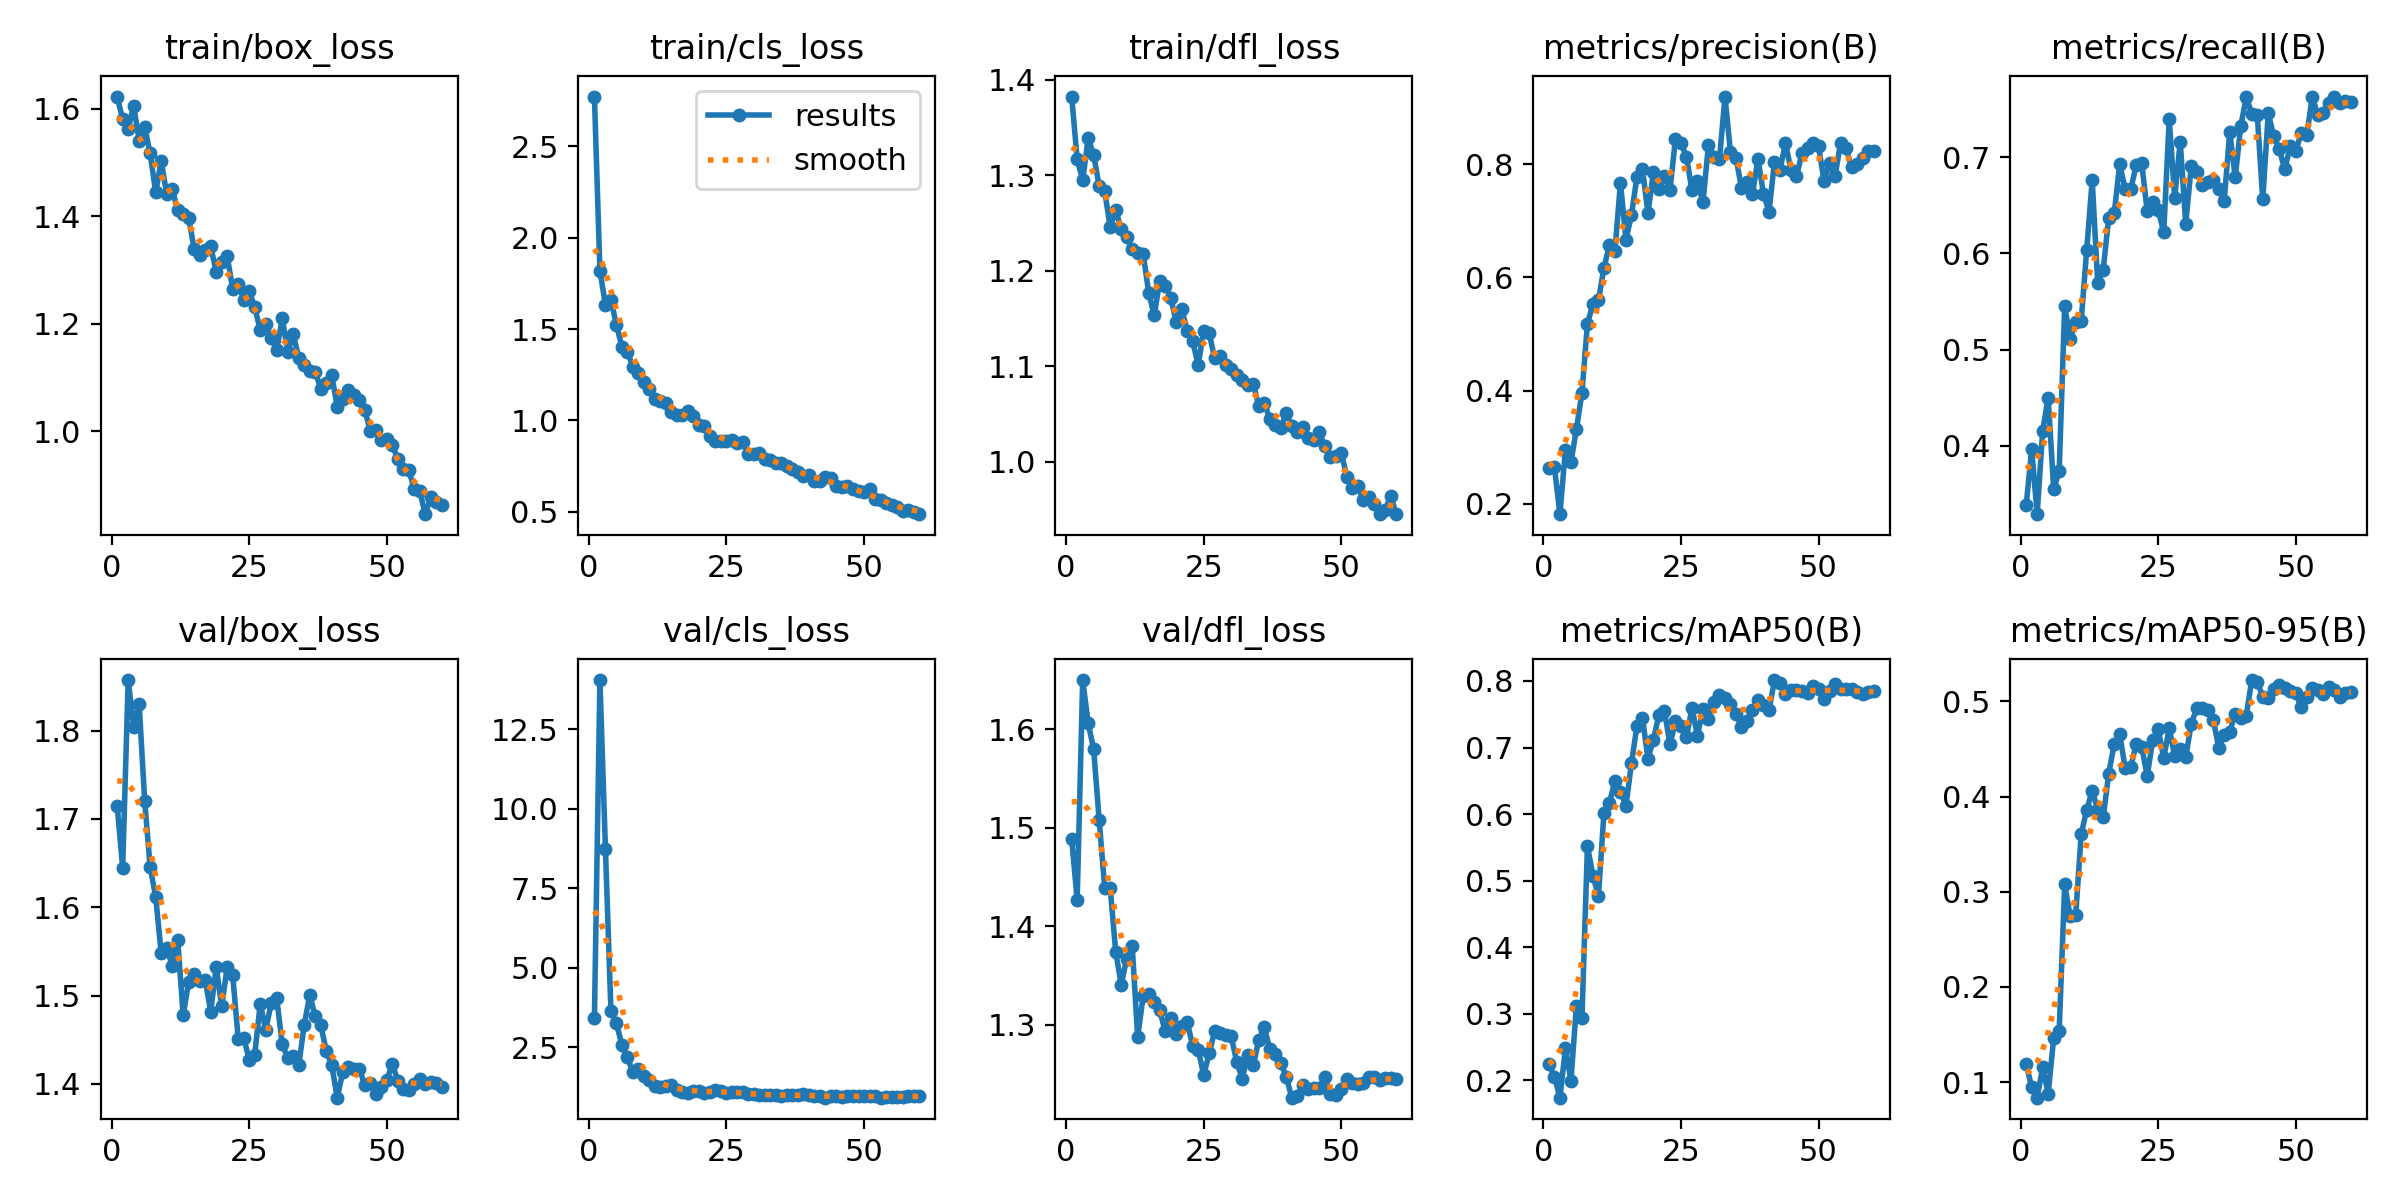

confusion_matrix_normalized.png


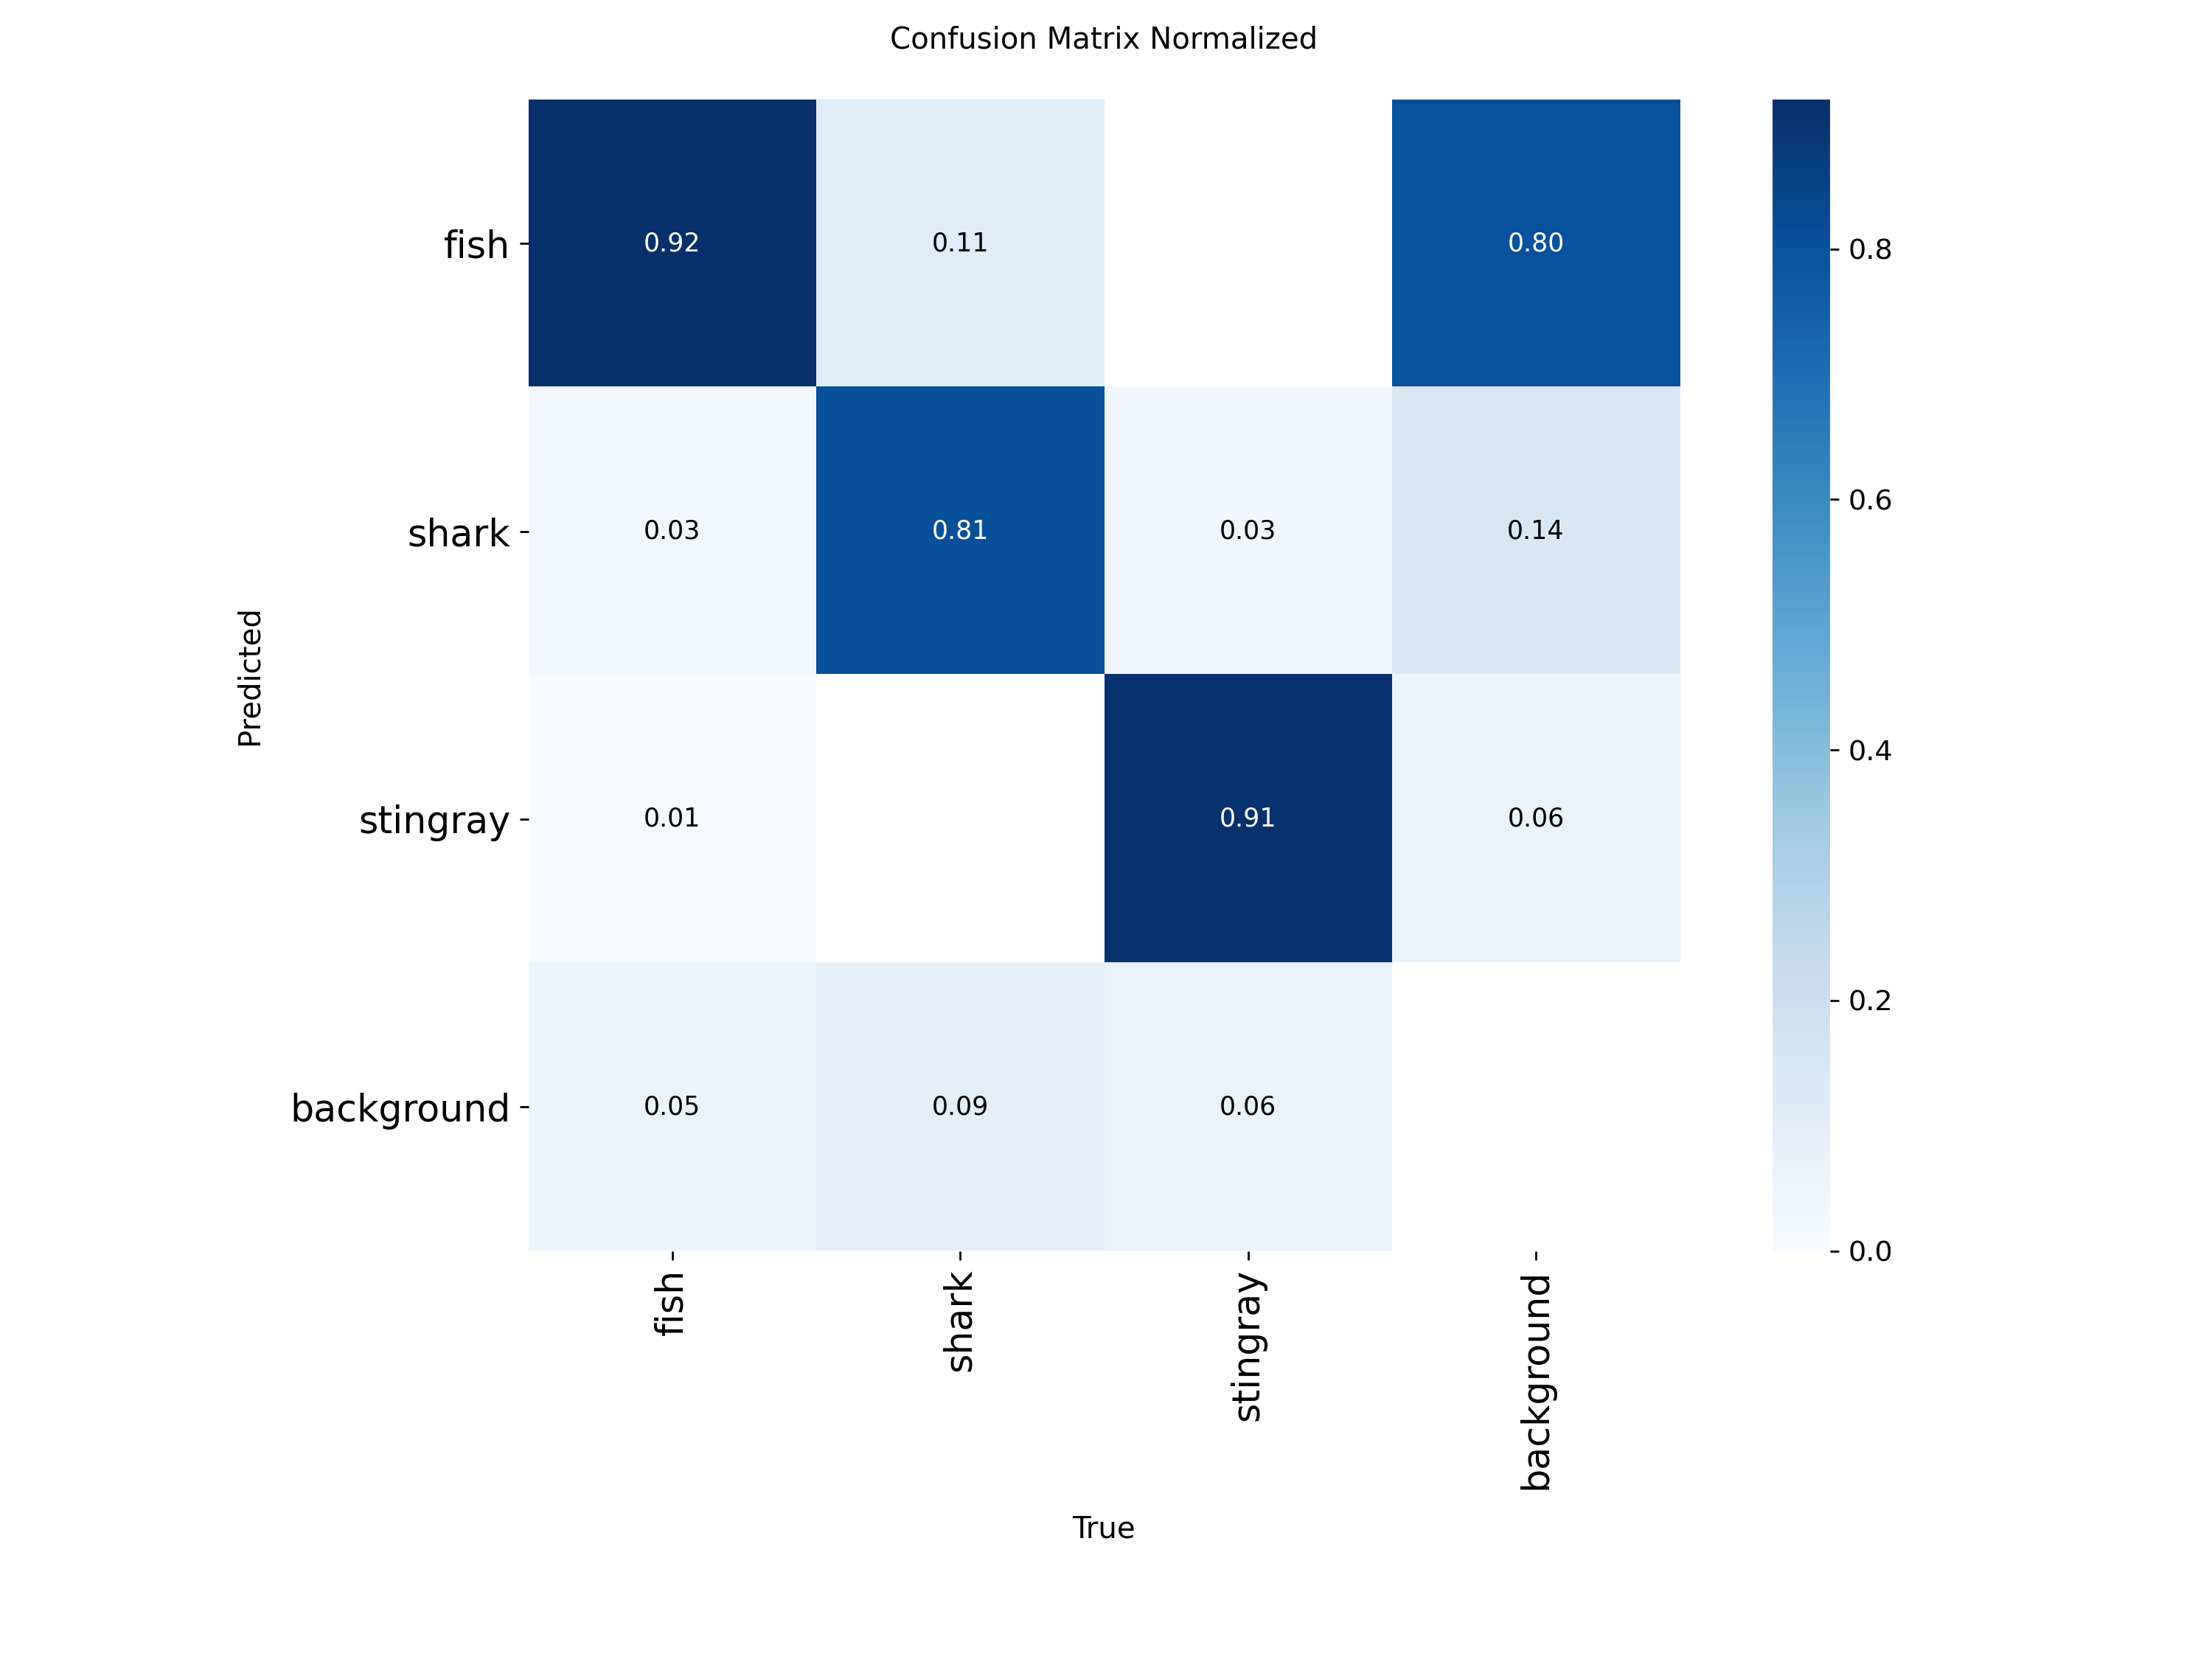

BoxPR_curve.png


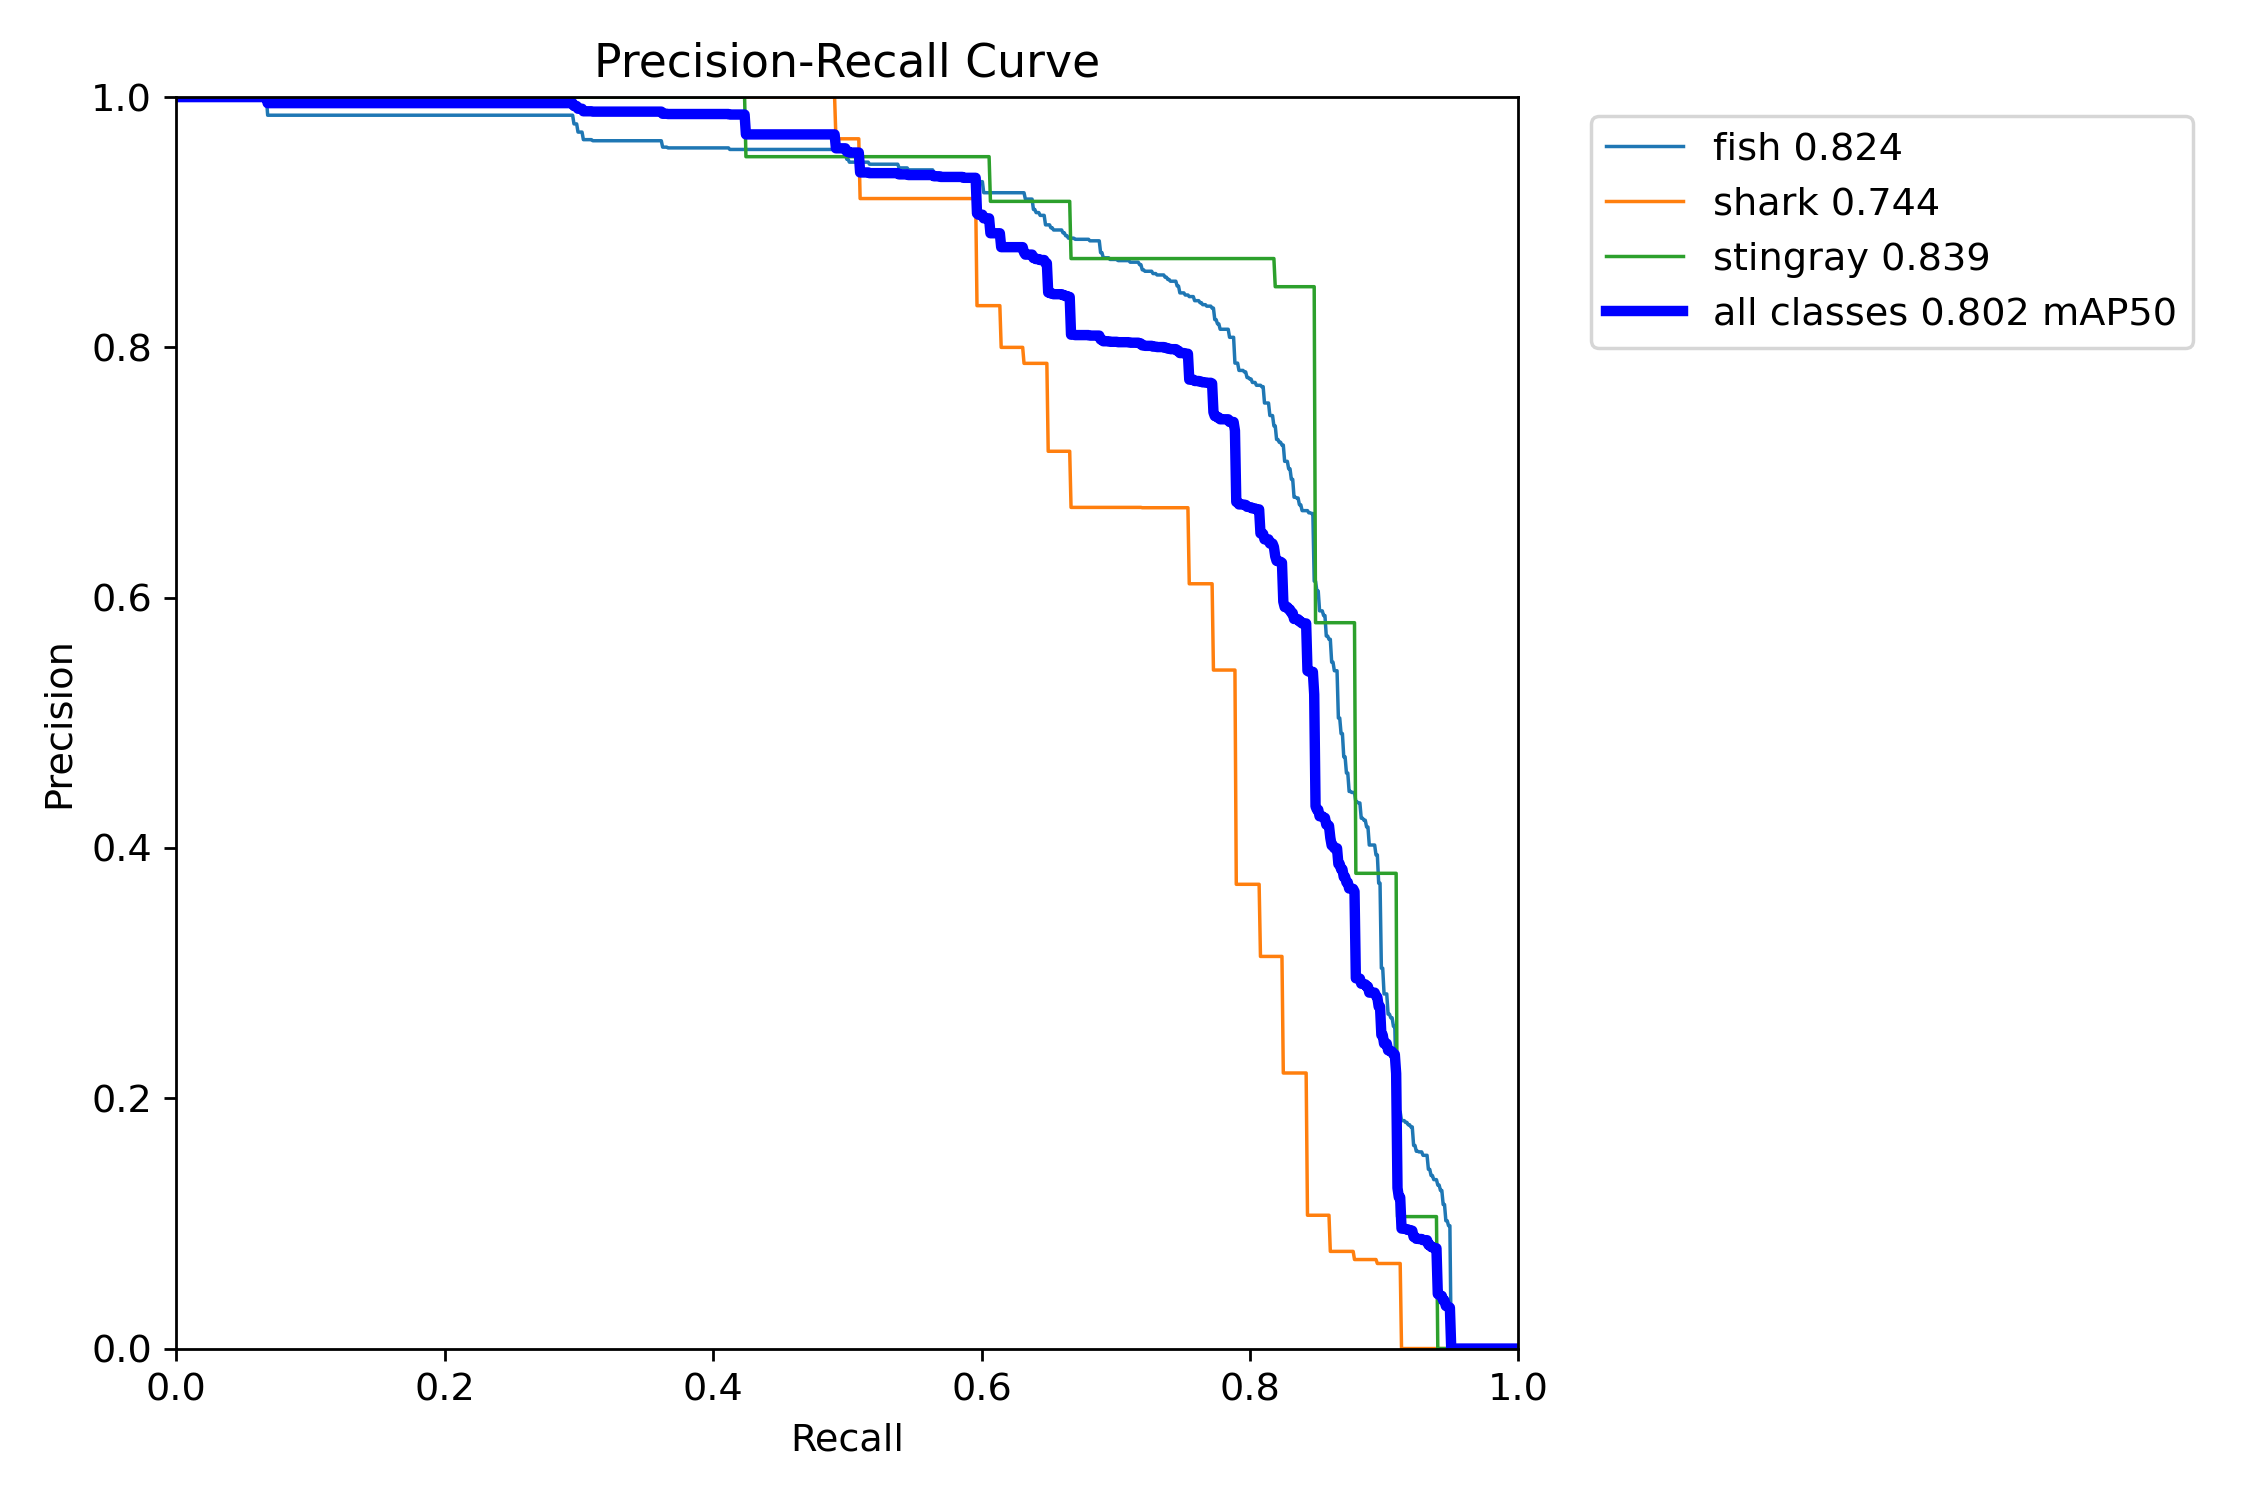

In [12]:
best_dir = RUNS_DIR / BEST_NAME                           # 선택된 실험의 결과 폴더
plot_files = [best_dir / "results.png",                   # 학습 곡선
              best_dir / "confusion_matrix_normalized.png"]   # 정규화된 혼동 행렬
plot_files += sorted(best_dir.glob("*PR_curve.png"))      # PR 곡선 (버전에 따라 파일 이름 앞부분이 다름)
for plot_path in plot_files:                              # 그림마다
    if plot_path.exists():                                # 파일이 있으면
        print(plot_path.name)                             # 파일 이름 출력
        display(Image(filename=str(plot_path), width=900))    # 노트북에 표시

## 9. fine-tuning 후: 같은 이미지로 다시 예측

5단계와 같은 이미지에 학습된 모델을 적용해 위아래로 비교합니다. 윗줄이 학습 전, 아랫줄이 학습 후입니다.

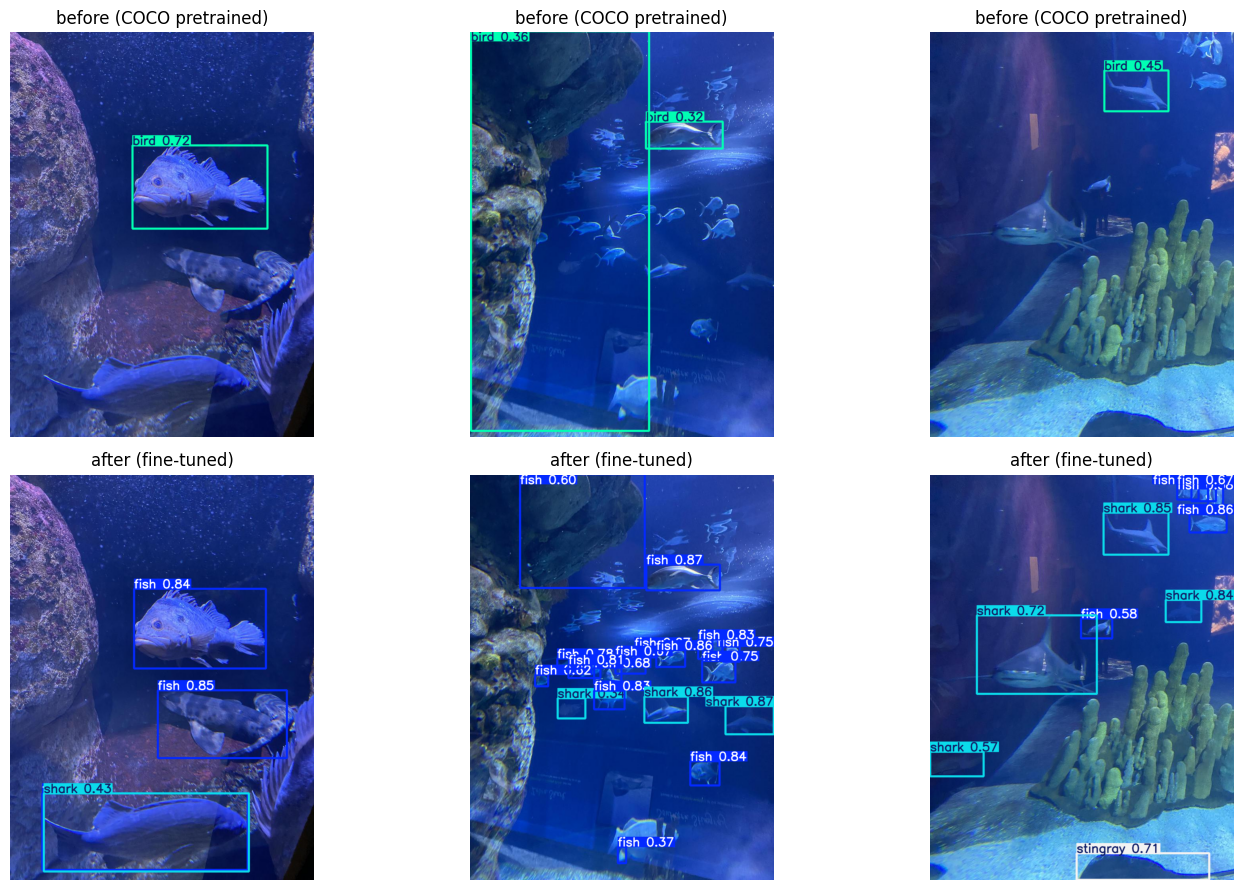

In [13]:
best_model = YOLO(str(BEST_WEIGHTS))                      # fine-tuning된 모델 불러오기
after_imgs = []                                           # 학습 후 예측 그림들
for img_path in demo_imgs:                                # 5단계와 같은 이미지
    result = best_model.predict(str(img_path), conf=0.25, verbose=False)[0]   # 예측 실행
    after_imgs.append(result.plot()[..., ::-1])           # 예측을 그린 그림 (BGR → RGB)

fig, axes = plt.subplots(2, len(demo_imgs), figsize=(15, 9), squeeze=False)   # 2행: 학습 전 / 학습 후
for col in range(len(demo_imgs)):                         # 이미지마다
    axes[0, col].imshow(before_imgs[col])                 # 윗줄: 학습 전
    axes[0, col].set_title("before (COCO pretrained)")    # 윗줄 제목
    axes[1, col].imshow(after_imgs[col])                  # 아랫줄: 학습 후
    axes[1, col].set_title("after (fine-tuned)")          # 아랫줄 제목
    axes[0, col].axis("off")                              # 축 숨김
    axes[1, col].axis("off")
plt.tight_layout()
plt.savefig(RUNS_DIR / "before_after.png", dpi=120)       # 보고서·README용으로 저장
plt.show()

## 10. 감지·추적 결과 5초 영상 만들기

**영상 준비**: [Pexels](https://www.pexels.com/videos/)나 [Pixabay](https://pixabay.com/videos/)에서 무료 영상을 받으세요.

- 4단계에서 고른 3개 부류가 나와야 합니다. 한 영상에 다 없으면 2~3개 영상으로 나눠 준비하면 됩니다.
- 대상이 화면에 크게 보이고 천천히 움직이는 장면이 잘 잡힙니다.
- 물고기 수십 마리가 떼 지어 나오는 장면은 추적 ID가 뒤섞이니 피하세요.
- 가로 영상, 1280×720 이상을 권합니다.

아래 셀을 실행해 영상을 올리세요. 왼쪽 파일 탐색기에서 `videos` 폴더에 직접 끌어다 놓아도 됩니다.
이미 올린 뒤라면 업로드 창에서 취소를 눌러도 됩니다.

In [14]:
VIDEO_EXTS = {".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v"}   # 영상으로 취급할 확장자
VIDEO_DIR.mkdir(exist_ok=True)                            # 영상 폴더 생성
if IN_COLAB:                                              # Colab이면 업로드 창 열기
    for video_name in files.upload():                     # 올린 파일 이름이 차례로 나옴
        shutil.move(video_name, VIDEO_DIR / video_name)   # videos 폴더로 이동


def video_info(path):
    """영상의 (길이 초, 너비, 높이, 초당 프레임 수)를 돌려준다."""
    cap = cv2.VideoCapture(str(path))                     # 영상 열기
    fps = cap.get(cv2.CAP_PROP_FPS) or 30                 # 초당 프레임 수 (못 읽으면 30으로 가정)
    n_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)          # 전체 프레임 수
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))        # 너비
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))      # 높이
    cap.release()                                         # 영상 닫기
    return n_frames / fps, width, height, fps


video_files = sorted(p for p in VIDEO_DIR.iterdir() if p.suffix.lower() in VIDEO_EXTS)   # 올라온 영상 목록
assert video_files, "videos 폴더에 영상이 없습니다. 영상을 올린 뒤 이 셀을 다시 실행하세요."
for path in video_files:                                  # 영상마다 정보 출력
    seconds, width, height, fps = video_info(path)
    print(f"{path.name}: {seconds:.1f}초, {width}x{height}, {fps:.0f}fps")

Saving 2556894-hd_1920_1080_25fps.mp4 to 2556894-hd_1920_1080_25fps.mp4
2556894-hd_1920_1080_25fps.mp4: 18.7초, 1920x1080, 25fps


**구간 지정**: `CLIPS`에 (파일 이름, 시작 초, 길이 초)를 적습니다. 길이의 합이 5초가 되게 하세요.

- `CLIPS = None`이면 올린 영상들을 앞에서부터 같은 길이로 잘라 합계 5초를 만듭니다.
- 예: `CLIPS = [("shark.mp4", 3.0, 2.5), ("jellyfish.mp4", 0.0, 2.5)]`

결과를 보고 대상이 잘 안 잡히면 시작 초를 바꾸거나 `CONF`를 낮춰 다시 실행하세요.
추적 ID가 자주 바뀌면 `TRACKER`를 바꿔 비교해 보세요. 이런 시도는 보고서의 "경험한 내용"에 쓸 수 있습니다.

In [15]:
CLIPS = [("2556894-hd_1920_1080_25fps.mp4", 3.0, 5.0)]    # None: 자동 / 직접 지정 예: [("shark.mp4", 3.0, 2.5), ("jellyfish.mp4", 0.0, 2.5)]
TOTAL_SEC = 5.0                # 최종 영상 길이 (과제 조건: 5초 분량)
TRACKER = "botsort.yaml"       # 추적 알고리즘: "botsort.yaml" 또는 "bytetrack.yaml"
CONF = 0.35                    # 이 확신도보다 낮은 감지는 버림 (강의자료 44쪽의 confidence 임계값)
OUT_W, OUT_H, OUT_FPS = 1280, 720, 30   # 최종 영상의 너비, 높이, 초당 프레임 수
TRAIL = 30                     # 이동 궤적으로 그릴 최근 프레임 수

if CLIPS is None:                                         # 자동 구간: 영상마다 같은 길이
    CLIPS = [(p.name, 0.0, TOTAL_SEC / len(video_files)) for p in video_files]
total = sum(c[2] for c in CLIPS)                          # 구간 길이의 합
print("사용할 구간:", CLIPS)
if abs(total - TOTAL_SEC) > 0.1:                          # 합이 5초와 다르면 알림
    print(f"주의: 구간 길이의 합이 {total:.1f}초입니다. 과제 조건은 {TOTAL_SEC:.0f}초 분량입니다.")

if WORK_DIR.exists():                                     # 이전 작업 파일이 있으면
    shutil.rmtree(WORK_DIR)                               # 지우고
WORK_DIR.mkdir()                                          # 새로 만듦


def cut_clip(src, start, duration, dst):
    """영상의 한 구간을 잘라 해상도와 프레임 수를 통일한 mp4로 저장한다."""
    vf = (f"scale={OUT_W}:{OUT_H}:force_original_aspect_ratio=decrease,"   # 비율을 유지하며 축소·확대
          f"pad={OUT_W}:{OUT_H}:(ow-iw)/2:(oh-ih)/2,"                      # 남는 부분은 검은 여백으로 채움
          f"fps={OUT_FPS}")                                                 # 초당 프레임 수 통일
    cmd = ["ffmpeg", "-y", "-loglevel", "error",          # 덮어쓰기 허용, 오류만 출력
           "-ss", str(start), "-t", str(duration),        # 시작 위치와 길이
           "-i", str(src), "-vf", vf, "-an",              # 입력 파일, 영상 필터, 소리 제거
           "-c:v", "libx264", "-crf", "18", "-pix_fmt", "yuv420p", str(dst)]   # H.264로 저장
    subprocess.run(cmd, check=True)                       # ffmpeg 실행 (실패하면 오류 발생)


clip_files = []                                           # 잘라낸 구간 파일들
for i, (video_name, start, duration) in enumerate(CLIPS): # 구간마다
    src = VIDEO_DIR / video_name                          # 원본 영상
    assert src.exists(), f"{video_name} 파일이 videos 폴더에 없습니다."
    dst = WORK_DIR / f"clip_{i + 1}.mp4"                  # 잘라낸 파일 이름
    cut_clip(src, start, duration, dst)                   # 구간 자르기
    clip_files.append(dst)

track_rows = []                                           # 프레임별 추적 기록 (CSV로 저장)
frames_with_det = 0                                       # 객체가 하나라도 잡힌 프레임 수
frame_no = 0                                              # 전체 프레임 번호
raw_video = WORK_DIR / "tracked_raw.mp4"                  # 그림을 그려 넣은 중간 영상
writer = cv2.VideoWriter(str(raw_video), cv2.VideoWriter_fourcc(*"mp4v"), OUT_FPS, (OUT_W, OUT_H))   # 영상 저장 도구

for clip_idx, clip_path in enumerate(clip_files):         # 잘라낸 구간마다
    track_model = YOLO(str(BEST_WEIGHTS))                 # 모델을 새로 불러와 추적기를 초기화
    trails = defaultdict(lambda: deque(maxlen=TRAIL))     # 추적 ID별 최근 중심점들
    cap = cv2.VideoCapture(str(clip_path))                # 구간 영상 열기
    while True:                                           # 프레임을 하나씩 처리
        ok, frame = cap.read()                            # 프레임 읽기
        if not ok:                                        # 더 읽을 프레임이 없으면
            break                                         # 이 구간 종료
        result = track_model.track(frame, persist=True, tracker=TRACKER,   # persist=True: 이전 프레임의 추적을 이어감
                                   conf=CONF, imgsz=IMGSZ, verbose=False)[0]
        canvas = result.plot(line_width=2)                # 상자, 추적 ID, 부류, 확신도가 그려진 프레임
        boxes = result.boxes                              # 이 프레임의 감지 결과
        if boxes.id is not None:                          # 추적 ID가 붙은 객체가 있으면
            frames_with_det += 1                          # 감지된 프레임 수 +1
            for (cx, cy, w, h), tid, cls, conf in zip(boxes.xywh.tolist(), boxes.id.int().tolist(),
                                                      boxes.cls.int().tolist(), boxes.conf.tolist()):
                trails[tid].append((int(cx), int(cy)))    # 중심점을 궤적에 추가
                track_rows.append({"frame": frame_no, "clip": clip_idx + 1, "track_id": tid,   # 기록 한 줄
                                   "class": track_model.names[cls], "conf": round(conf, 3),
                                   "cx": round(cx, 1), "cy": round(cy, 1), "w": round(w, 1), "h": round(h, 1)})
                if len(trails[tid]) > 1:                  # 점이 2개 이상이면 궤적 선 그리기
                    points = np.array(trails[tid], dtype=np.int32).reshape(-1, 1, 2)   # OpenCV가 받는 점 배열 형태
                    cv2.polylines(canvas, [points], False, (255, 255, 255), 2)         # 흰색 궤적
        writer.write(canvas)                              # 결과 프레임 저장
        frame_no += 1                                     # 프레임 번호 증가
    cap.release()                                         # 구간 영상 닫기
writer.release()                                          # 저장 마무리

FINAL_MP4 = WORK_DIR / "result_tracking.mp4"              # 최종 영상 (GitHub에서 바로 재생되는 H.264)
FINAL_GIF = WORK_DIR / "result_tracking.gif"              # README에 넣을 GIF
TRACKS_CSV = WORK_DIR / "tracks.csv"                      # 추적 궤적 기록
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(raw_video),
                "-c:v", "libx264", "-crf", "20", "-pix_fmt", "yuv420p",   # 브라우저에서 재생되는 형식
                "-movflags", "+faststart", str(FINAL_MP4)], check=True)
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(FINAL_MP4),
                "-vf", "fps=12,scale=640:-1:flags=lanczos,split[a][b];[a]palettegen[p];[b][p]paletteuse",   # 색상표를 만들어 GIF 화질 유지
                str(FINAL_GIF)], check=True)
track_cols = ["frame", "clip", "track_id", "class", "conf", "cx", "cy", "w", "h"]   # 추적 기록의 열 이름
tracks_df = pd.DataFrame(track_rows, columns=track_cols)  # 추적 기록 표 (감지가 없어도 열 이름은 유지)
tracks_df.to_csv(TRACKS_CSV, index=False)                 # 궤적 기록 저장

track_groups = tracks_df.groupby(["clip", "track_id"])["class"]        # 추적 ID별로 프레임마다 판정된 부류
major_class = track_groups.agg(lambda s: s.value_counts().idxmax())    # 추적 ID별로 가장 자주 나온 부류
class_changes = int((track_groups.nunique() > 1).sum())                # 도중에 부류 판정이 바뀐 추적 수
tracks_per_class = {name: int((major_class == name).sum()) for name in TARGET_CLASSES}   # 부류별 추적 객체 수

print(f"영상 길이: {frame_no / OUT_FPS:.1f}초 ({frame_no}프레임), 객체가 잡힌 프레임: {frames_with_det}개")
print(f"추적된 객체: {len(major_class)}개, 도중에 부류 판정이 바뀐 추적: {class_changes}개")
for cls_name in TARGET_CLASSES:                           # 부류마다 추적된 객체 수 출력
    n_ids = tracks_per_class[cls_name]                    # 그 부류로 추적된 객체 수
    note = "" if n_ids else "  ← 영상에서 잡히지 않았습니다. 구간이나 영상을 바꾸거나 CONF를 낮춰 보세요."
    print(f"  {cls_name}: 추적 ID {n_ids}개{note}")
display(Video(str(FINAL_MP4), embed=True, width=800))     # 노트북에서 결과 영상 재생

사용할 구간: [('2556894-hd_1920_1080_25fps.mp4', 3.0, 5.0)]
영상 길이: 5.0초 (150프레임), 객체가 잡힌 프레임: 118개
추적된 객체: 20개, 도중에 부류 판정이 바뀐 추적: 2개
  fish: 추적 ID 13개
  shark: 추적 ID 6개
  stingray: 추적 ID 1개


## 11. GitHub 제출 폴더 만들기

학습 모델, 결과 영상, 그래프, 지표를 한 폴더에 모으고 `README.md`를 자동으로 작성합니다.
README의 숫자는 모두 이 노트북에서 실제로 나온 결과입니다.

`VIDEO_SOURCE`에는 영상을 받은 곳을 적으세요.

In [16]:
VIDEO_SOURCE = "Pexels, Underwater Footage (Magda Ehlers), https://www.pexels.com/video/underwater-footage-2556894/"   # 결과 영상의 원본 출처 (받은 사이트나 주소로 바꾸세요)
DATASET_URL = f"https://universe.roboflow.com/{WORKSPACE}/{PROJECT}/dataset/{VERSION}"   # 데이터셋 주소


def to_markdown(df, digits=3):
    """표(DataFrame)를 마크다운 표 문자열로 바꾼다. 실수는 digits 자리까지, 분 단위 열은 한 자리까지."""
    header = "| " + " | ".join(str(c) for c in df.columns) + " |"     # 제목 줄
    divider = "|" + "---|" * len(df.columns)                          # 구분 줄
    body = []                                                         # 내용 줄들
    for _, row in df.iterrows():                                      # 행마다
        cells = []                                                    # 이 행의 칸들
        for col, value in row.items():                                # 칸마다
            if isinstance(value, float):                              # 실수면 자릿수를 맞춰 표기
                cells.append(f"{value:.1f}" if str(col).endswith("minutes") else f"{value:.{digits}f}")
            else:                                                     # 그 밖에는 그대로 문자열로
                cells.append(str(value))
        body.append("| " + " | ".join(cells) + " |")
    return "\n".join([header, divider] + body)


if OUT_DIR.exists():                                      # 이전 제출 폴더가 있으면
    shutil.rmtree(OUT_DIR)                                # 지우고 새로 만듦
for sub in ["weights", "videos", "results"]:              # 하위 폴더 생성
    (OUT_DIR / sub).mkdir(parents=True)

shutil.copy2(BEST_WEIGHTS, OUT_DIR / "weights" / "best.pt")            # 학습 모델
shutil.copy2(FINAL_MP4, OUT_DIR / "videos" / FINAL_MP4.name)           # 결과 영상 (mp4)
shutil.copy2(FINAL_GIF, OUT_DIR / "videos" / FINAL_GIF.name)           # 결과 영상 (gif)
shutil.copy2(DATA_YAML, OUT_DIR / "data.yaml")                         # 데이터 설정 파일
result_files = [RUNS_DIR / "metrics_test.csv", RUNS_DIR / "train_summary.csv",   # 지표와 학습 요약
                RUNS_DIR / "dataset_stats.csv", RUNS_DIR / "dataset_samples.png",   # 데이터 통계와 예시
                RUNS_DIR / "compare_curves.png", RUNS_DIR / "before_after.png",     # 실험 비교, 학습 전후 비교
                TRACKS_CSV,                                                         # 추적 궤적 기록
                best_dir / "results.png", best_dir / "confusion_matrix.png",        # 선택 모델의 학습 곡선, 혼동 행렬
                best_dir / "confusion_matrix_normalized.png"]
result_files += sorted(best_dir.glob("*PR_curve.png"))                 # 선택 모델의 PR 곡선
for src in result_files:                                  # 결과 파일마다
    if src.exists():                                      # 있으면
        shutil.copy2(src, OUT_DIR / "results" / src.name) # results 폴더로 복사
pr_names = [p.name for p in sorted(best_dir.glob("*PR_curve.png"))]    # PR 곡선 파일 이름
pr_line = f"![PR curve](results/{pr_names[0]})" if pr_names else ""    # README에 넣을 PR 곡선 줄

classes_text = ", ".join(TARGET_CLASSES)                               # 선택한 부류 이름을 쉼표로 연결
raw_names_text = ", ".join(raw_names)                                  # 원본 부류 이름을 쉼표로 연결
device_text = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"   # 학습에 쓴 장치 이름
video_seconds = frame_no / OUT_FPS                                     # 결과 영상 길이(초)
n_train_img, n_valid_img, n_test_img = (split_counts[k] for k in SPLITS)   # 분할별 이미지 수
stats_md = to_markdown(stats3.reset_index().rename(columns={"index": "class"}))   # 데이터 통계 표
summary_md = to_markdown(summary_df)                                   # 학습 요약 표
metrics_md = to_markdown(metrics_df)                                   # 성능 지표 표

readme = f"""# YOLOv8 fine-tuning: 수족관 생물 3개 부류 감지·추적

머신러닝 과제 2의 결과 저장소입니다. COCO로 사전학습된 YOLOv8을 3개 부류({classes_text})에 fine-tuning하고,
학습된 모델로 영상에서 객체를 감지·추적했습니다.

## 결과 영상

![tracking result](videos/{FINAL_GIF.name})

- 원본 화질 영상: [`videos/{FINAL_MP4.name}`](videos/{FINAL_MP4.name}) ({video_seconds:.1f}초)
- 상자 위의 숫자는 추적 ID이고, 흰 선은 최근 {TRAIL}프레임 동안의 이동 궤적입니다.
- 추적 알고리즘: `{TRACKER}`, confidence 임계값: {CONF}
- 프레임별 추적 기록: [`results/tracks.csv`](results/tracks.csv)
- 영상 원본 출처: {VIDEO_SOURCE}

## 데이터

- 출처: [Roboflow Aquarium Combined]({DATASET_URL}) 버전 {VERSION} (CC BY 4.0)
- 원본 부류 {len(raw_names)}개({raw_names_text}) 중 3개를 선택해 부류 번호를 다시 매겼습니다.
- 사용한 이미지: 총 {len(items3)}장 (train {n_train_img} / valid {n_valid_img} / test {n_test_img})

{stats_md}

![dataset samples](results/dataset_samples.png)

## 학습

- 사전학습 가중치: `{MODEL}` (COCO)
- 설정: epochs {EPOCHS} (patience {PATIENCE}), imgsz {IMGSZ}, batch {BATCH}, seed {SEED}
- 환경: Ultralytics {ultralytics.__version__}, {device_text}
- 실험 `full`: 모든 층을 학습
- 실험 `freeze`: 백본(앞 {FREEZE}개 층)을 고정하고 넥과 헤드만 학습

{summary_md}

![training curves comparison](results/compare_curves.png)

## 성능 (test 분할)

{metrics_md}

최종 모델은 검증 mAP50-95가 더 높은 `{BEST_NAME}` 실험의 가중치이며 [`weights/best.pt`](weights/best.pt)에 있습니다.

![results](results/results.png)
![confusion matrix](results/confusion_matrix_normalized.png)
{pr_line}

## fine-tuning 전후 비교

윗줄은 COCO 사전학습 모델, 아랫줄은 fine-tuning한 모델의 예측입니다.

![before and after](results/before_after.png)

## 사용 방법

```python
from ultralytics import YOLO

model = YOLO("weights/best.pt")
model.track("my_video.mp4", tracker="{TRACKER}", conf={CONF}, save=True)
```

## 파일 구성

- `weights/best.pt`: 학습된 모델
- `videos/`: 감지·추적 결과 영상 (mp4, gif)
- `results/`: 성능 지표, 학습 곡선, 혼동 행렬, 추적 기록
- `data.yaml`: 학습에 사용한 데이터 설정
"""
(OUT_DIR / "README.md").write_text(readme, encoding="utf-8")   # README 저장

zip_path = shutil.make_archive(str(OUT_DIR), "zip", OUT_DIR)   # 제출 폴더를 zip으로 묶기
print("제출 폴더:", OUT_DIR)
for path in sorted(OUT_DIR.rglob("*")):                   # 들어 있는 파일 목록 출력
    if path.is_file():
        print(f"  {path.relative_to(OUT_DIR)}  ({path.stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:                                              # Colab이면
    files.download(zip_path)                              # zip을 내 컴퓨터로 내려받기

제출 폴더: /content/submission
  README.md  (0.0 MB)
  data.yaml  (0.0 MB)
  results/BoxPR_curve.png  (0.1 MB)
  results/before_after.png  (1.7 MB)
  results/compare_curves.png  (0.1 MB)
  results/confusion_matrix.png  (0.1 MB)
  results/confusion_matrix_normalized.png  (0.1 MB)
  results/dataset_samples.png  (2.0 MB)
  results/dataset_stats.csv  (0.0 MB)
  results/metrics_test.csv  (0.0 MB)
  results/results.png  (0.3 MB)
  results/tracks.csv  (0.0 MB)
  results/train_summary.csv  (0.0 MB)
  videos/result_tracking.gif  (7.9 MB)
  videos/result_tracking.mp4  (2.4 MB)
  weights/best.pt  (22.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
readme_path = OUT_DIR / "README.md"                      # 11단계에서 만든 README
text = readme_path.read_text(encoding="utf-8")           # 내용 읽기
edits = [                                                # (찾을 문장, 바꿀 문장) 목록
    ("중 3개를 선택해 부류 번호를 다시 매겼습니다.",
     "중 3개를 선택해 부류 번호를 다시 매겼습니다.\n"
     "- fish 부류는 상어와 가오리를 제외한 일반 어류를 가리키며, 데이터셋의 라벨 정의를 그대로 따랐습니다."),
    ("![results](results/results.png)",
     "아래의 학습 곡선, 혼동 행렬, PR 곡선은 학습 중 검증(valid) 분할로 계산한 것입니다.\n\n"
     "![results](results/results.png)"),
]
for old, new in edits:                                   # 문장마다
    assert text.count(old) == 1, f"찾을 문장이 없거나 이미 수정됨: {old[:20]}"
    text = text.replace(old, new)                        # 바꾸기
readme_path.write_text(text, encoding="utf-8")           # 저장
final_zip = shutil.make_archive(str(BASE / "submission_final"), "zip", OUT_DIR)   # 최종 zip 만들기
print("README 수정 완료 →", final_zip)
files.download(final_zip)                                # 최종 zip 내려받기

README 수정 완료 → /content/submission_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. GitHub에 올리기

1. [github.com](https://github.com)에서 `New repository`를 눌러 저장소를 만듭니다. **Public**으로 설정하세요.
2. 내려받은 `submission.zip`의 압축을 풉니다.
3. 저장소 화면에서 `uploading an existing file`을 누르고, 압축을 푼 폴더 **안의 내용 전체**를 끌어다 놓은 뒤 `Commit changes`를 누릅니다.
4. 이 노트북도 `파일 → 다운로드 → .ipynb 다운로드`로 받아 같은 저장소에 올립니다.
5. 로그아웃한 창(시크릿 창)에서 저장소 주소를 열어 공개 상태인지, README의 영상과 그림이 보이는지 확인합니다.

브라우저 업로드는 파일 하나당 25MB까지입니다. `yolov8s` 기반의 `best.pt`는 약 22MB라서 올라가지만,
더 큰 모델(`yolov8m` 이상)로 바꿨다면 git 명령어로 올려야 합니다.

## 13. 결과보고서에 넣을 내용

아래 셀은 보고서에 옮겨 적을 숫자를 한곳에 모아 보여줍니다.

**1) 학습 과정 및 성능**
- 데이터: 출처, 선택한 3개 부류, 이미지 수와 분할 (4단계의 표, `dataset_samples.png`)
- 학습 설정과 두 실험의 차이 (6~7단계)
- 성능: test 지표 표, `compare_curves.png`, `results.png`, 혼동 행렬, PR 곡선 (8단계)
- fine-tuning 전후 비교 (`before_after.png`)

**2) GitHub 링크**: 12단계에서 만든 저장소 주소

**3) 과제 과정에서 경험한 내용**: 직접 겪은 일을 문제, 원인, 해결 순서로 적으세요. 살펴볼 만한 지점은 다음과 같습니다.
- 어떤 부류의 AP가 가장 낮았는지, 혼동 행렬에서 무엇과 헷갈렸는지
- 전체 학습과 백본 동결 학습의 성능·학습 시간 차이가 어땠는지
- 영상에서 추적 ID가 바뀌거나 놓친 장면이 있었는지, 구간·`CONF`·`TRACKER`를 바꿨을 때 어떻게 달라졌는지
- 학습 데이터(수족관 두 곳의 사진)와 내가 고른 영상의 환경 차이가 결과에 어떤 영향을 줬는지

In [ ]:
print("■ 데이터")
print(f"  부류: {TARGET_CLASSES}")
print(f"  이미지: 총 {len(items3)}장 (train {split_counts['train']} / valid {split_counts['valid']} / test {split_counts['test']})")
display(stats3)
print("■ 학습 설정")
print(f"  모델 {MODEL}, epochs {EPOCHS}, imgsz {IMGSZ}, batch {BATCH}, seed {SEED}, Ultralytics {ultralytics.__version__}")
display(summary_df)
print("■ 성능 (test 분할)")
display(metrics_df)
print("■ 추적 영상")
print(f"  길이 {frame_no / OUT_FPS:.1f}초, 추적기 {TRACKER}, conf {CONF}")
for cls_name in TARGET_CLASSES:
    print(f"  {cls_name}: 추적 ID {tracks_per_class[cls_name]}개")